# Trial Preprocessing — semua kombinasi langkah schema linking GraphRAG 2-Stage

Notebook ini menjalankan **semua kombinasi** lima langkah preprocessing GraphRAG 2-Stage di **satu pasangan threshold** (default T 0.50 / K 0.70), pada sampel 20% dev set per tingkat kesulitan (stratified, sama dengan `ablation.py`). Hasilnya bahan bab metodologi: apa efek tiap langkah, dan kenapa langkah itu dipakai atau tidak. Notebook ini **tidak memilih** kombinasi (poin 33, 42).

| Bagian | Isi |
|---|---|
| 1-4 | Setup, import, konfigurasi (`PREPROC_OPTIONS`), data + sampel + gold schema |
| 5 | EDA: struktur graph, ukuran gold schema, normalisasi nama, nama kolom ambigu |
| 6 | Index embedding |
| 7 | Walk-through 1 query (preprocessing `config.py`) |
| 8 | **Semua kombinasi**: SLA, kolom, dan token per kombinasi |
| 9 | **EX** per kombinasi (zero-shot, butuh GPU) |
| 10 | Kombinasi diurutkan menurut EX (urutan baca, bukan pilihan) |
| 11 | Error analysis satu kombinasi: kenapa kolom gold terlewat |
| 12 | Bandingkan dua kombinasi per query |
| 13 | Statistik indeks value linking |
| 14 | Oracle traversal: batas atas precision tiap mode traversal |
| 15 | Export Excel (`Trial Preprocessing`) |

Threshold T dan K dicari di `trial_thresholds.ipynb`. Kode bersama kedua notebook ada di `src/experiments/trial_steps.py`.

## 1. Setup

In [1]:
import os, subprocess
from pathlib import Path

REPO_URL = "https://github.com/william-darma-wijaya/thesis-2803.git"
REPO_BRANCH = "main"

def sh(cmd: str) -> None:
    print(f"$ {cmd}")
    subprocess.run(cmd, shell=True, check=True)

def is_repo_root(p: Path) -> bool:
    return (p / "src" / "core" / "config.py").is_file()

if not is_repo_root(Path.cwd()):
    if is_repo_root(Path.cwd().parent):      # dijalankan dari notebooks/
        os.chdir("..")
    else:                                    # Kaggle: clone dulu
        if not is_repo_root(Path("thesis-2803").resolve()):
            sh(f"git clone -b {REPO_BRANCH} {REPO_URL}")
        else:                                # sudah pernah di-clone: pastikan di branch yang benar
            sh(f"git -C thesis-2803 fetch origin {REPO_BRANCH} && git -C thesis-2803 checkout {REPO_BRANCH} && git -C thesis-2803 pull origin {REPO_BRANCH}")
        os.chdir("thesis-2803")
REPO_ROOT = Path.cwd()
assert is_repo_root(REPO_ROOT), f"{REPO_ROOT} bukan root repo thesis-2803"
print("Repo root:", REPO_ROOT)
print("Branch   :", subprocess.run("git rev-parse --abbrev-ref HEAD", shell=True, capture_output=True, text=True).stdout.strip())

# nltk dibutuhkan parser SQL Spider (process_sql.py); sentence-transformers untuk BGE-M3
sh("pip install -q -U 'bitsandbytes>=0.46.1' sentence-transformers transformers nltk openpyxl")
import nltk
for pkg in ("punkt", "punkt_tab"):
    try:
        nltk.download(pkg, quiet=True)
    except Exception as e:
        print(f"[WARN] nltk.download({pkg}) gagal: {e}")

$ git clone -b main https://github.com/william-darma-wijaya/thesis-2803.git


Cloning into 'thesis-2803'...


Repo root: /kaggle/working/thesis-2803
Branch   : main
$ pip install -q -U 'bitsandbytes>=0.46.1' sentence-transformers transformers nltk openpyxl


## 2. Import

In [2]:
import sys, json, time, shutil, subprocess
from collections import Counter
from dataclasses import replace

import numpy as np
import pandas as pd
import networkx as nx
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from sentence_transformers import util
from tqdm.auto import tqdm

sys.path.insert(0, str(REPO_ROOT))

from src.core.config import PipelineConfig
from src.core.schema import normalize_identifier
from src.retrieval.retrieval import (
    retrieve_candidate_tables, retrieve_graphrag_schema, column_nodes_to_schema, _extract_phrases, k_from_pct,
    value_linked_columns, trace_schema_paths, traversal_graph,
)
from src.retrieval.value_linking import get_value_index
from src.experiments import trial_steps as ts
from src.experiments import result_tables as rt
from src.experiments.result_tables import show
from src.metrics.sla import compute_sla, aggregate_sla
from src.utils.sampling import distribution_table

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)
print("Imports OK | CUDA:", torch.cuda.is_available())

Imports OK | CUDA: True


## 3. Konfigurasi

| Knob | Arti |
|---|---|
| `SAMPLE_RATIO` | fraksi dev set, diambil per tingkat kesulitan (stratified, poin 34) |
| `TABLE_THRESHOLD`, `COLUMN_THRESHOLD` | satu pasangan (T, K) untuk semua kombinasi |
| `PREPROC_OPTIONS` | nilai yang dicoba per langkah. **Semua kombinasinya dijalankan.** |
| `RUN_EX` | EX zero-shot tiap kombinasi (bagian 9, butuh GPU). `False` = tanpa LLM |

Langkah preprocessing:
- **stopword**: `none` = semua n-gram pertanyaan; `edge` = buang n-gram yang diawali/diakhiri stopword; `remove` = buang stopword dulu, baru n-gram.
- **value_link**: `off`; `text` = n-gram yang persis sama dengan nilai sel teks di DB menambahkan kolomnya sebagai anchor; `text + numbers` = ditambah angka/tahun.
- **traversal**: `full` = semua node di jalur terpendek antar anchor masuk prompt; `fk_only` = jalur sama, tapi hanya kolom JOIN.
- **no_pk**: `connected` = kolom tabel tanpa PK (tabel penghubung seperti `Has_Pet`) disambung di graph traversal, supaya JOIN lewat tabel itu bisa dilalui.
- **nama_embed**: `original` = nama kolom asli yang dinormalisasi (`stuid`); `natural` = nama anotasi Spider (`student id`). SQL dan DDL tetap nama asli.

**Biaya:** 2 x 3 x 2 x 2 x 2 = 48 kombinasi. Retrieval cepat, tetapi EX bisa sampai 48 x jumlah sampel generasi (dikurangi prompt yang sama). Kurangi nilai di `PREPROC_OPTIONS` kalau waktu GPU terbatas.

In [3]:
SAMPLE_RATIO = 0.20        # 20% per tingkat kesulitan, sama dengan ablation few-shot
TABLE_THRESHOLD = 0.50     # T, Stage 1
COLUMN_THRESHOLD = 0.70    # K, Stage 2
MAX_NGRAM = 2              # bigram (config.py)
# Nilai yang dicoba per langkah; semua kombinasinya dijalankan.
PREPROC_OPTIONS = {
    "stopword":   ["none", "edge"],                   # tambah "remove" untuk mencobanya juga
    "value_link": ["off", "text", "text + numbers"],
    "traversal":  ["full", "fk_only"],
    "no_pk":      ["not connected", "connected"],
    "nama_embed": ["original", "natural"],
}
EXCLUDE_EMPTY_GOLD = False # True = buang query yang gold schema-nya kosong (SELECT count(*) ...)
RUN_EX = True              # bagian 9: EX zero-shot tiap kombinasi (butuh GPU)

# Preprocessing lain mengikuti config.py; tiap kombinasi mengganti kelima langkah di atas
cfg = PipelineConfig(top_k_tables_pct=0, top_k_columns_pct=0, max_ngram=MAX_NGRAM,
                     table_similarity_threshold=TABLE_THRESHOLD, semantic_similarity_threshold=COLUMN_THRESHOLD)
cfg.data_path = ts.find_data_path(cfg, REPO_ROOT)
COMBOS = ts.all_combinations(PREPROC_OPTIONS)
print("Data path:", cfg.data_path)
print(f"{len(COMBOS)} kombinasi di T {TABLE_THRESHOLD:.2f} / K {COLUMN_THRESHOLD:.2f}")
print("Preprocessing config.py:", ts.describe(ts.settings_of(cfg)))

Data path: /kaggle/input/datasets/alrette/spiderdataset/spider_data
48 kombinasi di T 0.50 / K 0.70
Preprocessing config.py: stopword=edge, value_link=text, traversal=fk_only, no_pk=connected, nama_embed=natural


## 4. Load data, graph, sampel dev set, dan gold schema

In [4]:
data = ts.load_trial_data(cfg, SAMPLE_RATIO, EXCLUDE_EMPTY_GOLD)
# Nama pendek untuk sel EDA dan analisis di bawah
schema_df, graph, db_schema, samples, sample_dbs = data.schema_df, data.graph, data.db_schema, data.samples, data.sample_dbs
print(f"Dev set: {len(data.dev_data)} query | sampel: {len(data.indices)} | dipakai: {len(samples)} "
      f"| gold gagal di-parse: {data.n_failed} | gold kosong: {data.n_empty}")
print(f"Database di sampel: {len(sample_dbs)} dari {schema_df['Database'].nunique()}")
display(pd.DataFrame(distribution_table(data.dev_data, data.indices)).style.format(
    {"full_share": "{:.1%}", "sample_share": "{:.1%}"}).set_caption("Distribusi difficulty: dev penuh vs sampel"))

15:54:17 | INFO     | src.core.schema | Graph built: 4503 nodes, 3847 edges
15:54:18 | INFO     | src.retrieval.baseline | Table graph built: 876 table-nodes, 744 FK-edges
15:54:19 | INFO     | httpx | HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
15:54:19 | INFO     | httpx | HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2.5-Coder-7B-Instruct "HTTP/1.1 200 OK"
15:54:19 | INFO     | httpx | HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-7B-Instruct/resolve/c03e6d358207e414f1eca0bb1891e29f1db0e242/config.json "HTTP/1.1 307 Temporary Redirect"
15:54:19 | INFO     | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-7B-Instruct/c03e6d358207e414f1eca0bb1891e29f1db0e242/config.json?%2FQwen%2FQwen2.5-Coder-7B-Instruct%2Fresolve%2Fc03e6d358207e414f1eca0bb1891e29f1db0e242%2Fconfig.json=&etag=%221a2ea88621f4248fccfb575beaf64c1ea5d9587f%22 "HTTP/1.1 200 OK"
15:54:19 | INFO     | httpx | HTTP 

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

15:54:19 | INFO     | httpx | HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-7B-Instruct/resolve/c03e6d358207e414f1eca0bb1891e29f1db0e242/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
15:54:19 | WARNING  | huggingface_hub.utils._http | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
15:54:19 | INFO     | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-7B-Instruct/c03e6d358207e414f1eca0bb1891e29f1db0e242/tokenizer_config.json?%2FQwen%2FQwen2.5-Coder-7B-Instruct%2Fresolve%2Fc03e6d358207e414f1eca0bb1891e29f1db0e242%2Ftokenizer_config.json=&etag=%22acee076f49bf3c0298e15de0909d1da7b392f0c3%22 "HTTP/1.1 200 OK"
15:54:19 | INFO     | httpx | HTTP Request: GET https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-7B-Instruct/c03e6d358207e414f1eca0bb1891e29f1db0e242/tokenizer_config.json?%2FQwen%2FQwen2.5-Coder-7B-Instruct%2

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

15:54:19 | INFO     | httpx | HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2.5-Coder-7B-Instruct/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
15:54:19 | INFO     | httpx | HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2.5-Coder-7B-Instruct/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
15:54:19 | INFO     | httpx | HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-7B-Instruct/resolve/c03e6d358207e414f1eca0bb1891e29f1db0e242/vocab.json "HTTP/1.1 307 Temporary Redirect"
15:54:19 | INFO     | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-7B-Instruct/c03e6d358207e414f1eca0bb1891e29f1db0e242/vocab.json?%2FQwen%2FQwen2.5-Coder-7B-Instruct%2Fresolve%2Fc03e6d358207e414f1eca0bb1891e29f1db0e242%2Fvocab.json=&etag=%224783fe10ac3adce15ac8f358ef5462739852c569%22 "HTTP/1.1 200 OK"
15:54:19 | INFO     | httpx | HTTP Request: GET https://huggingface.co/api/res

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

... (3 outputs left out)

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

15:54:19 | INFO     | httpx | HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-7B-Instruct/resolve/c03e6d358207e414f1eca0bb1891e29f1db0e242/added_tokens.json "HTTP/1.1 404 Not Found"
15:54:19 | INFO     | httpx | HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-7B-Instruct/resolve/c03e6d358207e414f1eca0bb1891e29f1db0e242/special_tokens_map.json "HTTP/1.1 404 Not Found"
15:54:20 | INFO     | httpx | HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-7B-Instruct/resolve/c03e6d358207e414f1eca0bb1891e29f1db0e242/chat_template.jinja "HTTP/1.1 404 Not Found"
15:54:20 | INFO     | httpx | HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2.5-Coder-7B-Instruct "HTTP/1.1 200 OK"


Dev set: 1034 query | sampel: 207 | dipakai: 207 | gold gagal di-parse: 0 | gold kosong: 7
Database di sampel: 19 dari 166


,difficulty,full_n,full_share,sample_n,sample_share
0,easy,248,24.0%,50,24.2%
1,medium,446,43.1%,89,43.0%
2,hard,174,16.8%,35,16.9%
3,extra,166,16.1%,33,15.9%


## 5. EDA singkat

Empat pertanyaan yang dijawab di sini:
1. **Seperti apa graph-nya?** (ukuran per DB, jenis edge, komponen terpisah)
2. **Seberapa kecil gold schema?** Ini batas atas seberapa selektif retrieval boleh dibuat.
3. **Apa yang berubah setelah normalisasi nama?** (teks yang benar-benar di-embed)
4. **Nama kolom mana yang ambigu?** (`id`, `name` ada di banyak tabel, penyebab utama presisi turun)

### 5a. Struktur schema graph

Graph: 4503 node (kolom), 3847 edge
Edge per tipe: {'belongs_to_pk': 3055, 'foreign_key': 792}
DB dengan >1 komponen terpisah: 15 (komponen > tabel = ada kolom/tabel yang tidak terhubung ke PK, traversal tidak bisa menyambungnya)


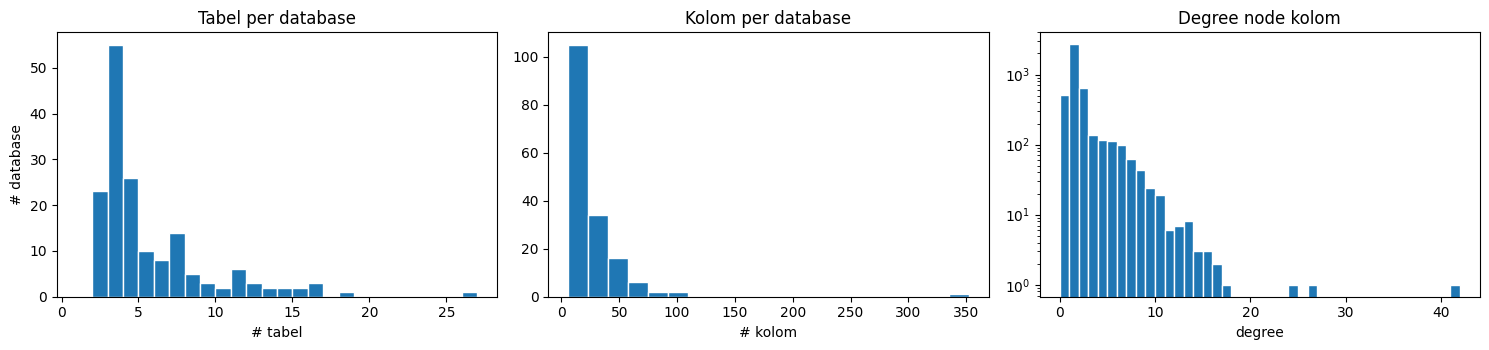

,tables,columns,edges,components,in_sample
db,,,,,
baseball_1,26,352,19,333,False
cre_Drama_Workshop_Groups,18,99,105,1,False
formula_1,13,94,98,3,False
sakila_1,16,89,94,2,False
soccer_1,7,86,83,5,False
hospital_1,15,68,78,1,False
imdb,16,66,59,7,False
store_1,12,66,63,3,False


In [5]:
rows = []
for db in schema_df["Database"].unique():
    sub = graph.subgraph([n for n, d in graph.nodes(data=True) if d["database"] == db])
    tables = {d["table"] for _, d in sub.nodes(data=True)}
    rows.append({
        "db": db, "tables": len(tables), "columns": sub.number_of_nodes(), "edges": sub.number_of_edges(),
        "components": nx.number_connected_components(sub),
    })
db_stats = pd.DataFrame(rows).set_index("db")
db_stats["in_sample"] = db_stats.index.isin(sample_dbs)

rel_counts = Counter(d.get("relation") for _, _, d in graph.edges(data=True))
print(f"Graph: {graph.number_of_nodes()} node (kolom), {graph.number_of_edges()} edge")
print("Edge per tipe:", dict(rel_counts))
print(f"DB dengan >1 komponen terpisah: {(db_stats['components'] > db_stats['tables']).sum()} "
      "(komponen > tabel = ada kolom/tabel yang tidak terhubung ke PK, traversal tidak bisa menyambungnya)")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(db_stats["tables"], bins=range(1, int(db_stats["tables"].max()) + 2), edgecolor="white")
ax[0].set(title="Tabel per database", xlabel="# tabel", ylabel="# database")
ax[1].hist(db_stats["columns"], bins=20, edgecolor="white")
ax[1].set(title="Kolom per database", xlabel="# kolom")
deg = [d for _, d in graph.degree()]
ax[2].hist(deg, bins=range(0, max(deg) + 2), edgecolor="white")
ax[2].set(title="Degree node kolom", xlabel="degree", yscale="log")
plt.tight_layout(); plt.show()
display(db_stats.sort_values("columns", ascending=False).head(8))

### 5b. Ukuran gold schema vs ukuran database

              mean    50%  min    max
gold_tables   1.52   1.00  0.0   3.00
gold_cols     2.77   3.00  0.0   7.00
db_tables     4.65   4.00  2.0  11.00
db_cols      25.35  23.00  7.0  56.00
gold_ratio    0.15   0.12  0.0   0.67

Rata-rata gold memakai 15.2% kolom DB -> retrieval ideal hanya perlu mengirim sebagian kecil schema.


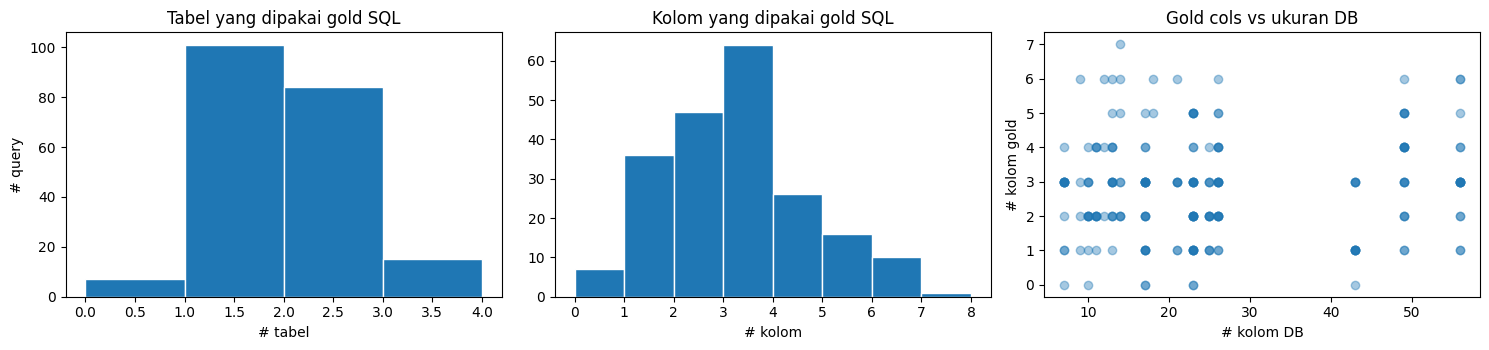

In [6]:
gold_rows = []
for qid, item, gold in samples:
    db = item["db_id"]
    n_db_cols = len(db_schema[db])
    gold_rows.append({
        "qid": qid, "db_id": db,
        "gold_tables": len({g.split(".", 1)[0] for g in gold}),
        "gold_cols": len(gold),
        "db_tables": len({c.split(".", 1)[0] for c in db_schema[db]}),
        "db_cols": n_db_cols,
        "gold_ratio": len(gold) / n_db_cols,
    })
gold_df = pd.DataFrame(gold_rows)
print(gold_df[["gold_tables", "gold_cols", "db_tables", "db_cols", "gold_ratio"]].describe().round(2).T[["mean", "50%", "min", "max"]])
print(f"\nRata-rata gold memakai {gold_df['gold_ratio'].mean():.1%} kolom DB -> retrieval ideal hanya perlu mengirim sebagian kecil schema.")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(gold_df["gold_tables"], bins=range(0, gold_df["gold_tables"].max() + 2), edgecolor="white")
ax[0].set(title="Tabel yang dipakai gold SQL", xlabel="# tabel", ylabel="# query")
ax[1].hist(gold_df["gold_cols"], bins=range(0, gold_df["gold_cols"].max() + 2), edgecolor="white")
ax[1].set(title="Kolom yang dipakai gold SQL", xlabel="# kolom")
ax[2].scatter(gold_df["db_cols"], gold_df["gold_cols"], alpha=0.4)
ax[2].set(title="Gold cols vs ukuran DB", xlabel="# kolom DB", ylabel="# kolom gold")
plt.tight_layout(); plt.show()

### 5c. Efek normalisasi nama (teks yang di-embed)

Embedding memakai `normalize_identifier()` (`src/core/schema.py`): `_` jadi spasi, camelCase dipecah, lowercase. Di bawah: contoh sebelum/sesudah, dan nama yang **masih** terlihat seperti singkatan (kandidat masalah karena BGE-M3 tidak bisa menebak `stu` = `student`).

In [7]:
cols_all = schema_df[schema_df["Column"] != "*"][["Database", "Table", "Column"]].drop_duplicates()
# Sama dengan build_schema_index(): default hanya nama kolom (EMBED_TABLE_PREFIX=False)
cols_all["embedded_text"] = cols_all["Column"].map(normalize_identifier)
changed = cols_all[cols_all["Column"].str.lower() != cols_all["Column"].map(normalize_identifier)]
print(f"Nama kolom yang berubah oleh normalisasi: {len(changed)} / {len(cols_all)} ({len(changed)/len(cols_all):.0%})")
display(changed.sample(12, random_state=cfg.seed)[["Table", "Column", "embedded_text"]].reset_index(drop=True))

# Heuristik kasar: token hasil normalisasi yang sangat pendek (<=3 huruf) dan bukan kata umum -> kemungkinan singkatan
COMMON_SHORT = {"id", "no", "the", "of", "and", "for", "age", "age", "key", "ref", "url", "tel", "dob", "sex", "day",
                "end", "fee", "net", "due", "tax", "age", "bed", "map", "set", "top", "low", "max", "min", "avg",
                "sum", "num", "per", "pct", "ssn", "gpa", "zip", "net", "win", "won", "lost", "loss", "tie", "pts"}
tok = Counter()
for c in cols_all["Column"].map(normalize_identifier):
    for w in c.split():
        if w.isalpha() and len(w) <= 3 and w not in COMMON_SHORT:
            tok[w] += 1
print("\nToken pendek yang paling sering muncul (cek apakah singkatan):")
print(", ".join(f"{w}({n})" for w, n in tok.most_common(25)))

Nama kolom yang berubah oleh normalisasi: 2918 / 4503 (65%)


,Table,Column,embedded_text
0,Other_Property_Features,property_feature_description,property feature description
1,Organizations,organization_name,organization name
2,weather,max_visibility_miles,max visibility miles
3,matches,winner_ioc,winner ioc
4,broadcast_share,Share_in_percent,share in percent
5,district,District_ID,district id
6,performance,Official_ratings_(millions),official ratings (millions)
7,Participants,Participant_Details,participant details
8,Services,Workshop_Group_ID,workshop group id
9,Customers,Customer_Name,customer name



Token pendek yang paling sering muncul (cek apakah singkatan):
in(35), g(34), stu(29), to(23), l(15), by(13), apt(11), yn(9), log(9), emp(9), aid(8), did(8), f(8), is(8), res(8), cmi(8), api(8), hr(7), cid(7), r(7), up(7), pid(6), job(6), all(6), w(6)


### 5d. Nama kolom ambigu (muncul di banyak tabel)

In [8]:
amb = (cols_all.assign(col_l=cols_all["Column"].str.lower())
       .groupby(["Database", "col_l"])["Table"].nunique().reset_index(name="n_tables"))
amb = amb[amb["n_tables"] > 1]
print(f"Pasangan (DB, nama kolom) yang ada di >1 tabel: {len(amb)}")
top_names = amb.groupby("col_l")["Database"].count().sort_values(ascending=False).head(12)
print("Nama kolom paling sering ambigu:", dict(top_names))
print("-> Embedding kolom hanya memakai nama kolom, jadi kolom senama di tabel kandidat berbeda dapat skor yang sama;\n"
      "   tabelnya dibedakan oleh Stage 1 dan node id (db.table.column) yang dipakai traversal.")

Pasangan (DB, nama kolom) yang ada di >1 tabel: 756
Nama kolom paling sering ambigu: {'name': np.int64(46), 'id': np.int64(18), 'customer_id': np.int64(17), 'product_id': np.int64(14), 'other_details': np.int64(10), 'address_id': np.int64(10), 'stuid': np.int64(9), 'year': np.int64(7), 'order_id': np.int64(7), 'country': np.int64(7), 'state': np.int64(7), 'staff_id': np.int64(6)}
-> Embedding kolom hanya memakai nama kolom, jadi kolom senama di tabel kandidat berbeda dapat skor yang sama;
   tabelnya dibedakan oleh Stage 1 dan node id (db.table.column) yang dipakai traversal.


## 6. Bangun index embedding

Index kolom dibangun sekali per (DB, sumber nama), dan embedding n-gram pertanyaan di-cache, jadi 48 kombinasi tidak meng-encode ulang hal yang sama.

In [9]:
data = ts.load_embedder(data)
for db in tqdm(sample_dbs, desc="Index kolom"):
    for names in PREPROC_OPTIONS["nama_embed"]:
        ts.index_for(data, db, replace(cfg, **ts.knobs_of({"nama_embed": names})))
print("Selesai.")

15:54:22 | INFO     | sentence_transformers.base.model | No device provided, using cuda:0
15:54:22 | INFO     | httpx | HTTP Request: GET https://huggingface.co/api/models/BAAI/bge-m3 "HTTP/1.1 200 OK"
15:54:22 | INFO     | httpx | HTTP Request: HEAD https://huggingface.co/BAAI/bge-m3/resolve/5617a9f61b028005a4858fdac845db406aefb181/modules.json "HTTP/1.1 307 Temporary Redirect"
15:54:22 | INFO     | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/BAAI/bge-m3/5617a9f61b028005a4858fdac845db406aefb181/modules.json?%2FBAAI%2Fbge-m3%2Fresolve%2F5617a9f61b028005a4858fdac845db406aefb181%2Fmodules.json=&etag=%22952a9b81c0bfd99800fabf352f69c7ccd46c5e43%22 "HTTP/1.1 200 OK"
15:54:22 | INFO     | httpx | HTTP Request: GET https://huggingface.co/api/resolve-cache/models/BAAI/bge-m3/5617a9f61b028005a4858fdac845db406aefb181/modules.json?%2FBAAI%2Fbge-m3%2Fresolve%2F5617a9f61b028005a4858fdac845db406aefb181%2Fmodules.json=&etag=%22952a9b81c0bfd99800fabf352f69c7ccd46c5e43%22

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

15:54:22 | INFO     | httpx | HTTP Request: HEAD https://huggingface.co/BAAI/bge-m3/resolve/5617a9f61b028005a4858fdac845db406aefb181/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
15:54:22 | INFO     | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/BAAI/bge-m3/5617a9f61b028005a4858fdac845db406aefb181/config_sentence_transformers.json?%2FBAAI%2Fbge-m3%2Fresolve%2F5617a9f61b028005a4858fdac845db406aefb181%2Fconfig_sentence_transformers.json=&etag=%221fba91c78a6c8e17227058ab6d4d3acb5d8630a9%22 "HTTP/1.1 200 OK"
15:54:22 | INFO     | httpx | HTTP Request: GET https://huggingface.co/api/resolve-cache/models/BAAI/bge-m3/5617a9f61b028005a4858fdac845db406aefb181/config_sentence_transformers.json?%2FBAAI%2Fbge-m3%2Fresolve%2F5617a9f61b028005a4858fdac845db406aefb181%2Fconfig_sentence_transformers.json=&etag=%221fba91c78a6c8e17227058ab6d4d3acb5d8630a9%22 "HTTP/1.1 200 OK"


config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

15:54:22 | INFO     | sentence_transformers.base.model | Loading SentenceTransformer model from BAAI/bge-m3.
15:54:22 | INFO     | httpx | HTTP Request: HEAD https://huggingface.co/BAAI/bge-m3/resolve/5617a9f61b028005a4858fdac845db406aefb181/README.md "HTTP/1.1 307 Temporary Redirect"
15:54:22 | INFO     | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/BAAI/bge-m3/5617a9f61b028005a4858fdac845db406aefb181/README.md?%2FBAAI%2Fbge-m3%2Fresolve%2F5617a9f61b028005a4858fdac845db406aefb181%2FREADME.md=&etag=%22e5a320176edd6ee1cfb256e68ee5ac0004de9447%22 "HTTP/1.1 200 OK"
15:54:22 | INFO     | httpx | HTTP Request: GET https://huggingface.co/api/resolve-cache/models/BAAI/bge-m3/5617a9f61b028005a4858fdac845db406aefb181/README.md?%2FBAAI%2Fbge-m3%2Fresolve%2F5617a9f61b028005a4858fdac845db406aefb181%2FREADME.md=&etag=%22e5a320176edd6ee1cfb256e68ee5ac0004de9447%22 "HTTP/1.1 200 OK"


README.md:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

... (99 outputs left out)

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Selesai.


## 7. Walk-through 1 query (preprocessing `config.py`)

Lihat apa yang dilakukan tiap tahap untuk satu pertanyaan. Ganti `QUERY_POS` (posisi di daftar sampel) untuk query lain.
- **Stage 1**: skor tiap tabel (max cosine lintas n-gram), top-k jadi kandidat.
- **Stage 2**: skor tiap kolom di tabel kandidat; lolos threshold, lalu di-cap.
- **Traversal**: node tambahan di jalur terpendek antar kolom terpilih (untuk JOIN).

In [10]:
def stage_scores(question, db_id, cfg):
    """Replikasi skor Stage 1 & 2 (sama dengan retrieval.py) untuk keperluan inspeksi."""
    idx = ts.index_for(data, db_id, cfg)
    phrases = _extract_phrases(question, cfg.max_ngram, cfg.query_stopword_mode, cfg.query_stopwords)
    phrase_emb = data.embedder.encode(phrases, convert_to_tensor=True)

    t_scores = util.cos_sim(phrase_emb, idx.table_embeddings).max(dim=0).values
    cand = retrieve_candidate_tables(question, idx, data.embedder, cfg)

    cand_set = set(cand)
    mask = [t in cand_set for t in idx.col_table_map]
    ids = [n for n, m in zip(idx.col_node_ids, mask) if m]
    c_scores = util.cos_sim(phrase_emb, idx.col_embeddings[torch.tensor(mask)]).max(dim=0).values
    return idx, cand, t_scores, ids, c_scores

def short(node):  # "db.table.column" -> "table.column" (lowercase, format SLA)
    d = graph.nodes[node]
    return f"{d['table'].lower()}.{d['column'].lower()}"

QUERY_POS = 0
qid, item, gold = samples[QUERY_POS]
q, db = item["question"], item["db_id"]
idx, cand, t_scores, ids, c_scores = stage_scores(q, db, cfg)

print(f"[{QUERY_POS}] db={db}\nQ    : {q}\nSQL  : {item['query']}\nGold : {sorted(gold)}\n")

print(f"Stage 1 — {len(cand)} dari {len(idx.tables)} tabel lolos (table threshold={cfg.table_similarity_threshold}, tables_pct={cfg.top_k_tables_pct}):")
for i in torch.argsort(t_scores, descending=True).tolist():
    t = idx.tables[i]
    mark = "KANDIDAT" if t in cand else "        "
    gold_mark = "  <- gold" if any(g.startswith(t.lower() + ".") for g in gold) else ""
    print(f"  {mark} {t_scores[i].item():.3f}  {t}{gold_mark}")

k_c = k_from_pct(cfg.top_k_columns_pct, len(ids))
order = torch.argsort(c_scores, descending=True).tolist()
print(f"\nStage 2 — {len(ids)} kolom di tabel kandidat, cap={k_c}, threshold={cfg.semantic_similarity_threshold}:")
for r, i in enumerate(order[:15]):
    s = c_scores[i].item()
    keep = s >= cfg.semantic_similarity_threshold and r < k_c
    print(f"  {'KEEP' if keep else '    '} {s:.3f}  {short(ids[i])}{'  <- gold' if short(ids[i]) in gold else ''}")

column_nodes, _ = retrieve_graphrag_schema(graph, db, q, idx, data.embedder, cfg)
pred = set(column_nodes_to_schema(graph, column_nodes))
detected = {short(ids[i]) for i in order[:k_c] if c_scores[i].item() >= cfg.semantic_similarity_threshold}
linked = {short(n) for n in value_linked_columns(graph, db, q, cfg)} if cfg.use_value_linking else set()
print(f"\nValue linking      : {sorted(linked) if cfg.use_value_linking else '(mati)'}")
print(f"Ditambah traversal : {sorted(pred - detected - linked)}")
print(f"Prediksi final     : {sorted(pred)}")
print(f"Terlewat (FN)      : {sorted(gold - pred)}")
print(f"Berlebih (FP)      : {sorted(pred - gold)}")
for lvl in ("table", "column"):
    r = compute_sla(gold, pred, level=lvl)
    print(f"SLA {lvl:<6}: P={r.precision:.2f} R={r.recall:.2f} F1={r.f1:.2f}")

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

[0] db=concert_singer
Q    : Show all countries and the number of singers in each country.
SQL  : SELECT country ,  count(*) FROM singer GROUP BY country
Gold : ['singer.country']

Stage 1 — 4 dari 4 tabel lolos (table threshold=0.5, tables_pct=0):
  KANDIDAT 0.866  singer  <- gold
  KANDIDAT 0.775  singer_in_concert
  KANDIDAT 0.686  concert
  KANDIDAT 0.605  stadium

Stage 2 — 21 kolom di tabel kandidat, cap=21, threshold=0.7:
  KEEP 1.000  singer.country  <- gold
  KEEP 0.752  singer_in_concert.singer_id
  KEEP 0.752  singer.singer_id
  KEEP 0.720  singer.song_name
       0.682  singer.name
       0.682  stadium.name
       0.664  concert.year
       0.659  stadium.capacity
       0.641  stadium.location
       0.634  singer.age
       0.633  singer.song_release_year
       0.607  stadium.average
       0.600  concert.concert_name
       0.593  stadium.highest
       0.586  concert.theme

Value linking      : []
Ditambah traversal : []
Prediksi final     : ['singer.country', 'singer

## 8. Semua kombinasi: SLA, kolom, dan token

Satu baris = satu kombinasi, semuanya di (T, K) yang sama dan sampel yang sama. Rekap lengkap (termasuk median dan perbandingan dengan DDL penuh) tersimpan di `outputs/tables/trial_preprocessing_recap.csv` dan sheet Excel `Trial Preprocessing`; tabel di bawah hanya kolom inti. Arti tiap kolom: `context/TRIAL_COLUMNS_EXPLAINED.md`.

In [11]:
TRIALS = [ts.two_stage_trial(cfg, s, TABLE_THRESHOLD, COLUMN_THRESHOLD) for s in COMBOS]
TRIAL_CACHE = globals().get("TRIAL_CACHE", {})     # hasil per query yang sudah dihitung, dipakai ulang kalau sel dijalankan lagi
recap, RESULTS = ts.run_trials(data, TRIALS, TRIAL_CACHE, progress=lambda x: tqdm(x, desc="Kombinasi"))
print("Rekap ->", ts.save_recap(recap, REPO_ROOT / "outputs" / "tables", ts.PREPROCESSING_RECAP))
print(f"n = {len(samples)} query | T {TABLE_THRESHOLD:.2f} / K {COLUMN_THRESHOLD:.2f} | MAX_NGRAM = {cfg.max_ngram}")
display(ts.styled_recap(recap))

Kombinasi:   0%|          | 0/48 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

... (406 outputs left out)

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Rekap -> /kaggle/working/thesis-2803/outputs/tables/trial_preprocessing_recap.csv
n = 207 query | T 0.50 / K 0.70 | MAX_NGRAM = 2


,pipeline,table_threshold,column_threshold,stopword,value_link,traversal,no_pk,nama_embed,col_P_ne,col_R_ne,tbl_R,cols_sent,tables_pct,cols_pct,schema_tokens,prompt_tokens_k0,prompt_red_db
trial,,,,,,,,,,,,,,,,,
"2-stage | stopword=none, value_link=off, traversal=full, no_pk=not connected, nama_embed=original | T0.50/K0.70",graphrag,0.50,0.70,none,off,full,not connected,original,39.2%,87.7%,94.4%,8.4,72.7%,36.2%,96.6,284.4,28.9%
"2-stage | stopword=none, value_link=off, traversal=full, no_pk=not connected, nama_embed=natural | T0.50/K0.70",graphrag,0.50,0.70,none,off,full,not connected,natural,39.4%,89.5%,94.5%,8.6,72.8%,37.1%,98.1,285.9,28.6%
"2-stage | stopword=none, value_link=off, traversal=full, no_pk=connected, nama_embed=original | T0.50/K0.70",graphrag,0.50,0.70,none,off,full,connected,original,39.3%,88.4%,94.4%,8.6,73.0%,36.6%,99.0,286.8,28.3%
"2-stage | stopword=none, value_link=off, traversal=full, no_pk=connected, nama_embed=natural | T0.50/K0.70",graphrag,0.50,0.70,none,off,full,connected,natural,39.3%,89.5%,94.5%,8.7,73.2%,37.3%,100.2,288.0,28.0%
"2-stage | stopword=none, value_link=off, traversal=fk_only, no_pk=not connected, nama_embed=original | T0.50/K0.70",graphrag,0.50,0.70,none,off,fk_only,not connected,original,40.9%,87.4%,94.4%,8.0,72.7%,34.5%,93.1,280.9,29.8%
"2-stage | stopword=none, value_link=off, traversal=fk_only, no_pk=not connected, nama_embed=natural | T0.50/K0.70",graphrag,0.50,0.70,none,off,fk_only,not connected,natural,41.1%,89.3%,94.5%,8.1,72.8%,35.6%,94.7,282.5,29.4%
"2-stage | stopword=none, value_link=off, traversal=fk_only, no_pk=connected, nama_embed=original | T0.50/K0.70",graphrag,0.50,0.70,none,off,fk_only,connected,original,40.9%,88.2%,94.4%,8.2,73.0%,35.1%,95.8,283.6,29.1%
"2-stage | stopword=none, value_link=off, traversal=fk_only, no_pk=connected, nama_embed=natural | T0.50/K0.70",graphrag,0.50,0.70,none,off,fk_only,connected,natural,40.9%,89.3%,94.5%,8.3,73.2%,35.9%,97.0,284.8,28.8%
"2-stage | stopword=none, value_link=text, traversal=full, no_pk=not connected, nama_embed=original | T0.50/K0.70",graphrag,0.50,0.70,none,text,full,not connected,original,39.9%,91.8%,95.5%,8.6,73.3%,37.2%,98.1,285.9,28.5%


## 9. EX per kombinasi (zero-shot, butuh GPU)

- **Zero-shot:** k belum dipilih pada tahap ini, dan tanpa contoh few-shot beda EX hanya berasal dari beda schema. Prompt-nya sama persis dengan `prompt_tokens_k0`, jadi EX dan token di satu baris berasal dari prompt yang sama. Yang dibaca adalah **perbandingan antar konfigurasi**, bukan EX akhir.
- **Prompt yang identik hanya digenerate sekali** (greedy, deterministik) dan disimpan di `outputs/tables/sla_trial_ex_cache.jsonl`, dipakai bersama kedua notebook trial. Jalankan ulang sel ini untuk melanjutkan run yang terputus; di Kaggle, unduh file cache itu supaya tidak hilang.
- **Tidak memilih apa pun** (poin 33). EX dihitung di dev, jadi ikut dalam limitation poin 34.

In [12]:
if RUN_EX:
    recap, llm = ts.score_ex(recap, RESULTS, cfg, data.tokenizer, REPO_ROOT / ts.EX_CACHE, globals().get("llm"),
                             progress=lambda x: tqdm(x, desc="EX"))
    ts.save_recap(recap, REPO_ROOT / "outputs" / "tables", ts.PREPROCESSING_RECAP)
display(ts.styled_recap(recap))

15:56:02 | INFO     | httpx | HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2.5-Coder-7B-Instruct "HTTP/1.1 200 OK"
15:56:02 | INFO     | httpx | HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2.5-Coder-7B-Instruct/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
15:56:02 | INFO     | httpx | HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2.5-Coder-7B-Instruct/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
15:56:02 | INFO     | httpx | HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2.5-Coder-7B-Instruct "HTTP/1.1 200 OK"
15:56:02 | INFO     | httpx | HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2.5-Coder-7B-Instruct "HTTP/1.1 200 OK"
15:56:02 | INFO     | httpx | HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-7B-Instruct/resolve/c03e6d358207e414f1eca0bb1891e29f1db0e242/adapter_config.json "HTTP/1.1 404 Not Found"
15:56:02 | INFO     | httpx | HTTP Req

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

15:56:02 | INFO     | httpx | HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2.5-Coder-7B-Instruct/tree/c03e6d358207e414f1eca0bb1891e29f1db0e242?recursive=true&expand=false "HTTP/1.1 200 OK"


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

15:56:03 | INFO     | httpx | HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2.5-Coder-7B-Instruct/xet-read-token/c03e6d358207e414f1eca0bb1891e29f1db0e242 "HTTP/1.1 200 OK"


... (5 outputs left out)

EX:   0%|          | 0/48 [00:00<?, ?it/s]

[transformers] The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Digenerate: 504 | dari cache: 9432 | gagal (dihitung salah): 0


,pipeline,table_threshold,column_threshold,stopword,value_link,traversal,no_pk,nama_embed,ex,col_P_ne,col_R_ne,tbl_R,cols_sent,tables_pct,cols_pct,schema_tokens,prompt_tokens_k0,prompt_red_db
trial,,,,,,,,,,,,,,,,,,
"2-stage | stopword=none, value_link=off, traversal=full, no_pk=not connected, nama_embed=original | T0.50/K0.70",graphrag,0.50,0.70,none,off,full,not connected,original,58.9%,39.2%,87.7%,94.4%,8.4,72.7%,36.2%,96.6,284.4,28.9%
"2-stage | stopword=none, value_link=off, traversal=full, no_pk=not connected, nama_embed=natural | T0.50/K0.70",graphrag,0.50,0.70,none,off,full,not connected,natural,59.9%,39.4%,89.5%,94.5%,8.6,72.8%,37.1%,98.1,285.9,28.6%
"2-stage | stopword=none, value_link=off, traversal=full, no_pk=connected, nama_embed=original | T0.50/K0.70",graphrag,0.50,0.70,none,off,full,connected,original,58.9%,39.3%,88.4%,94.4%,8.6,73.0%,36.6%,99.0,286.8,28.3%
"2-stage | stopword=none, value_link=off, traversal=full, no_pk=connected, nama_embed=natural | T0.50/K0.70",graphrag,0.50,0.70,none,off,full,connected,natural,59.4%,39.3%,89.5%,94.5%,8.7,73.2%,37.3%,100.2,288.0,28.0%
"2-stage | stopword=none, value_link=off, traversal=fk_only, no_pk=not connected, nama_embed=original | T0.50/K0.70",graphrag,0.50,0.70,none,off,fk_only,not connected,original,58.9%,40.9%,87.4%,94.4%,8.0,72.7%,34.5%,93.1,280.9,29.8%
"2-stage | stopword=none, value_link=off, traversal=fk_only, no_pk=not connected, nama_embed=natural | T0.50/K0.70",graphrag,0.50,0.70,none,off,fk_only,not connected,natural,59.9%,41.1%,89.3%,94.5%,8.1,72.8%,35.6%,94.7,282.5,29.4%
"2-stage | stopword=none, value_link=off, traversal=fk_only, no_pk=connected, nama_embed=original | T0.50/K0.70",graphrag,0.50,0.70,none,off,fk_only,connected,original,58.9%,40.9%,88.2%,94.4%,8.2,73.0%,35.1%,95.8,283.6,29.1%
"2-stage | stopword=none, value_link=off, traversal=fk_only, no_pk=connected, nama_embed=natural | T0.50/K0.70",graphrag,0.50,0.70,none,off,fk_only,connected,natural,59.4%,40.9%,89.3%,94.5%,8.3,73.2%,35.9%,97.0,284.8,28.8%
"2-stage | stopword=none, value_link=text, traversal=full, no_pk=not connected, nama_embed=original | T0.50/K0.70",graphrag,0.50,0.70,none,text,full,not connected,original,62.3%,39.9%,91.8%,95.5%,8.6,73.3%,37.2%,98.1,285.9,28.5%


## 10. Kombinasi diurutkan menurut EX

Urutan baca, bukan pilihan. Selisih EX beberapa poin persen pada 207 pertanyaan bisa berupa noise (1 pertanyaan = 0.48 pp); bacalah bersama recall, precision, dan token.

In [13]:
if "ex" in recap.columns:
    display(ts.styled_recap(recap.sort_values(["ex", "col_R_ne"], ascending=False)))
else:
    print("Kolom EX belum ada: jalankan bagian 9 dengan RUN_EX = True.")

,pipeline,table_threshold,column_threshold,stopword,value_link,traversal,no_pk,nama_embed,ex,col_P_ne,col_R_ne,tbl_R,cols_sent,tables_pct,cols_pct,schema_tokens,prompt_tokens_k0,prompt_red_db
trial,,,,,,,,,,,,,,,,,,
"2-stage | stopword=edge, value_link=text + numbers, traversal=full, no_pk=connected, nama_embed=original | T0.50/K0.70",graphrag,0.50,0.70,edge,text + numbers,full,connected,original,65.7%,40.5%,94.0%,95.6%,8.7,73.4%,37.5%,100.5,288.3,28.0%
"2-stage | stopword=none, value_link=text + numbers, traversal=full, no_pk=not connected, nama_embed=natural | T0.50/K0.70",graphrag,0.50,0.70,none,text + numbers,full,not connected,natural,65.2%,39.8%,96.4%,96.5%,8.9,74.0%,38.7%,101.0,288.8,27.8%
"2-stage | stopword=none, value_link=text + numbers, traversal=fk_only, no_pk=not connected, nama_embed=natural | T0.50/K0.70",graphrag,0.50,0.70,none,text + numbers,fk_only,not connected,natural,65.2%,41.9%,96.3%,96.5%,8.5,74.0%,37.1%,97.4,285.2,28.7%
"2-stage | stopword=none, value_link=text + numbers, traversal=full, no_pk=connected, nama_embed=original | T0.50/K0.70",graphrag,0.50,0.70,none,text + numbers,full,connected,original,65.2%,39.6%,95.2%,96.3%,8.9,74.4%,38.3%,102.2,290.0,27.5%
"2-stage | stopword=edge, value_link=text + numbers, traversal=full, no_pk=not connected, nama_embed=natural | T0.50/K0.70",graphrag,0.50,0.70,edge,text + numbers,full,not connected,natural,65.2%,40.6%,95.2%,95.7%,8.7,73.0%,38.0%,99.4,287.2,28.2%
"2-stage | stopword=edge, value_link=text + numbers, traversal=full, no_pk=connected, nama_embed=natural | T0.50/K0.70",graphrag,0.50,0.70,edge,text + numbers,full,connected,natural,65.2%,40.4%,95.2%,95.7%,8.8,73.6%,38.3%,101.7,289.4,27.7%
"2-stage | stopword=none, value_link=text + numbers, traversal=full, no_pk=not connected, nama_embed=original | T0.50/K0.70",graphrag,0.50,0.70,none,text + numbers,full,not connected,original,65.2%,39.7%,94.5%,96.3%,8.8,73.8%,37.9%,99.5,287.3,28.2%
"2-stage | stopword=edge, value_link=text + numbers, traversal=full, no_pk=not connected, nama_embed=original | T0.50/K0.70",graphrag,0.50,0.70,edge,text + numbers,full,not connected,original,65.2%,40.4%,93.3%,95.6%,8.6,72.9%,37.1%,97.9,285.7,28.6%
"2-stage | stopword=none, value_link=text + numbers, traversal=full, no_pk=connected, nama_embed=natural | T0.50/K0.70",graphrag,0.50,0.70,none,text + numbers,full,connected,natural,64.7%,39.6%,96.4%,96.5%,9.0,74.5%,39.0%,103.3,291.1,27.3%


## 11. Error analysis — kenapa kolom gold terlewat?

Setiap kolom gold yang **tidak** ada di prediksi diberi satu alasan, diperiksa berurutan:

| Alasan | Arti | Knob yang relevan |
|---|---|---|
| `stage1_table_miss` | tabelnya sendiri tidak masuk top-k Stage 1 | `TABLES_PCT` naik, atau teks embed tabel kurang informatif |
| `below_threshold` | tabel lolos, tapi skor kolom < threshold | threshold kolom diturunkan, atau nama kolom sulit dipahami embedder |
| `cut_by_cap` | lolos threshold, tapi peringkatnya di luar cap | `COLUMNS_PCT` naik |
| `other` | tidak masuk walau lolos semua (mis. fallback / kasus tepi) | cek manual |

Kolom gold yang **berhasil** masuk dibedakan: `hit_stage2` (dipilih langsung), `hit_value_link` (masuk karena nilainya disebut di pertanyaan, bila `VALUE_LINKING = True`), dan `hit_via_traversal` (hanya karena ada di jalur JOIN).

Kombinasi yang dianalisis diatur `DIAG_SETTINGS` (default = preprocessing `config.py`).

Kombinasi: stopword=edge, value_link=text, traversal=fk_only, no_pk=connected, nama_embed=natural
Total kolom gold: 573


,jumlah,persen
reason,,
hit_stage2,462,80.6%
hit_value_link,19,3.3%
hit_via_traversal,50,8.7%
below_threshold,40,7.0%
cut_by_cap,0,0.0%
stage1_table_miss,2,0.3%
other,0,0.0%


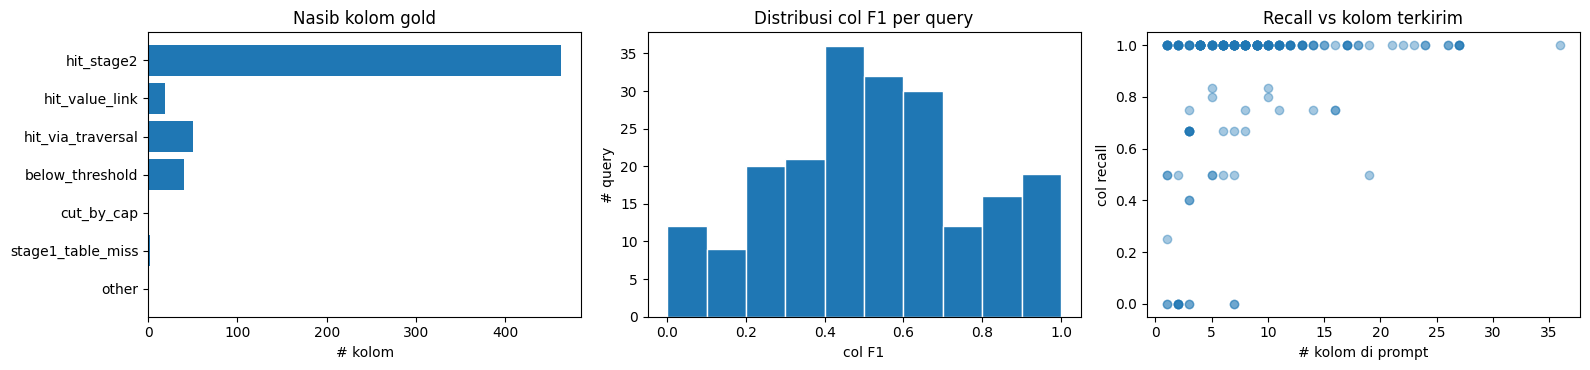

Skor kolom gold yang terlewat karena below_threshold (dekat threshold = cukup turunkan threshold):


,count,mean,std,min,25%,50%,75%,max
score,40.0,0.615,0.052,0.46,0.586,0.622,0.658,0.697


In [14]:
DIAG_SETTINGS = ts.settings_of(cfg)     # ganti, mis. {**ts.settings_of(cfg), "value_link": "text + numbers"}
diag_cfg = replace(cfg, **ts.knobs_of(DIAG_SETTINGS))
per_query = pd.DataFrame(RESULTS[ts.two_stage_trial(cfg, DIAG_SETTINGS, TABLE_THRESHOLD, COLUMN_THRESHOLD)[0]])
print("Kombinasi:", ts.describe(DIAG_SETTINGS))
def diagnose(cfg, samples=samples):
    rows = []
    for qid, item, gold in samples:
        db, q = item["db_id"], item["question"]
        idx, cand, _, ids, c_scores = stage_scores(q, db, cfg)
        cand_l = {t.lower() for t in cand}
        order = torch.argsort(c_scores, descending=True).tolist()
        k_c = k_from_pct(cfg.top_k_columns_pct, len(ids))
        rank = {short(ids[i]): r for r, i in enumerate(order)}
        score = {short(ids[i]): c_scores[i].item() for i in range(len(ids))}
        nodes, _ = retrieve_graphrag_schema(graph, db, q, idx, data.embedder, cfg)
        pred = set(column_nodes_to_schema(graph, nodes))
        detected = {c for c, r in rank.items() if r < k_c and score[c] >= cfg.semantic_similarity_threshold}
        linked = {short(n) for n in value_linked_columns(graph, db, q, cfg)} if cfg.use_value_linking else set()
        for g_col in gold:
            t = g_col.split(".", 1)[0]
            if g_col in pred:
                reason = ("hit_stage2" if g_col in detected
                          else "hit_value_link" if g_col in linked else "hit_via_traversal")
            elif t not in cand_l:
                reason = "stage1_table_miss"
            elif score.get(g_col, -1) < cfg.semantic_similarity_threshold:
                reason = "below_threshold"
            elif rank.get(g_col, 10**9) >= k_c:
                reason = "cut_by_cap"
            else:
                reason = "other"
            rows.append({"qid": qid, "db_id": db, "question": q, "gold_col": g_col, "reason": reason,
                         "score": score.get(g_col), "rank": rank.get(g_col), "cap": k_c})
    return pd.DataFrame(rows)

diag = diagnose(diag_cfg)
order_reasons = ["hit_stage2", "hit_value_link", "hit_via_traversal", "below_threshold", "cut_by_cap", "stage1_table_miss", "other"]
counts = diag["reason"].value_counts().reindex(order_reasons, fill_value=0)
print(f"Total kolom gold: {len(diag)}")
display(pd.DataFrame({"jumlah": counts, "persen": (counts / len(diag)).map("{:.1%}".format)}))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].barh(counts.index[::-1], counts.values[::-1])
ax[0].set(title="Nasib kolom gold", xlabel="# kolom")
ax[1].hist(per_query["col_F1"], bins=10, range=(0, 1), edgecolor="white")
ax[1].set(title="Distribusi col F1 per query", xlabel="col F1", ylabel="# query")
ax[2].scatter(per_query["cols_sent"], per_query["col_R"], alpha=0.4)
ax[2].set(title="Recall vs kolom terkirim", xlabel="# kolom di prompt", ylabel="col recall")
plt.tight_layout(); plt.show()

misses = diag[~diag["reason"].str.startswith("hit")]
print("Skor kolom gold yang terlewat karena below_threshold (dekat threshold = cukup turunkan threshold):")
display(misses[misses["reason"] == "below_threshold"]["score"].describe().round(3).to_frame().T)

Query dengan F1 kolom terendah, untuk dilihat manual (apa yang terlewat, apa yang berlebih):

In [15]:
worst = per_query.sort_values(["col_F1", "col_R"]).head(10).copy()
worst["missed"] = [sorted(set(g) - set(p)) for g, p in zip(worst["gold"], worst["pred"])]
worst["extra"] = [sorted(set(p) - set(g)) for g, p in zip(worst["gold"], worst["pred"])]
display(worst[["qid", "db_id", "question", "col_F1", "missed", "extra"]].reset_index(drop=True))

,qid,db_id,question,col_F1,missed,extra
0,21,concert_singer,How many concerts occurred in 2014 or 2015?,0.0,[concert.year],"[concert.concert_id, concert.concert_name, singer_in_concert.concert_id]"
1,142,car_1,What model has the most different versions?,0.0,[car_names.model],"[model_list.model, model_list.modelid]"
2,146,car_1,"In 1980, how many cars were made?",0.0,[cars_data.year],"[car_makers.id, car_makers.maker, car_names.make, car_names.makeid, car_names.model, m..."
3,259,employee_hire_evaluation,How many employees are there?,0.0,[],"[employee.employee_id, evaluation.employee_id, hiring.employee_id]"
4,358,cre_Doc_Template_Mgt,Count the number of paragraphs.,0.0,[],"[documents.document_id, documents.template_id, paragraphs.document_id, paragraphs.para..."
5,382,course_teach,What is the total count of teachers?,0.0,[],"[course_arrange.teacher_id, teacher.teacher_id]"
6,430,wta_1,How many players are there?,0.0,[],"[players.player_id, rankings.player_id]"
7,450,wta_1,How many matches were played in 2013 or 2016?,0.0,[matches.year],[matches.match_num]
8,822,orchestra,How many conductors are there?,0.0,[],"[conductor.conductor_id, orchestra.conductor_id]"
9,823,orchestra,Count the number of conductors.,0.0,[],"[conductor.conductor_id, orchestra.conductor_id]"


Detail alasan untuk kolom gold yang terlewat (urut dari skor tertinggi = paling dekat lolos):

In [16]:
display(misses.sort_values("score", ascending=False)
        [["qid", "db_id", "gold_col", "reason", "score", "rank", "cap", "question"]].head(15).reset_index(drop=True))

,qid,db_id,gold_col,reason,score,rank,cap,question
0,702,world_1,country.indepyear,below_threshold,0.696532,3.0,24,What are the names of all the countries that became independent after 1950?
1,961,dog_kennels,dogs.age,below_threshold,0.680599,11.0,47,Who owns the youngest dog? Give me his or her last name.
2,1027,singer,singer.name,below_threshold,0.679802,3.0,10,What is the sname of every sing that does not have any song?
3,713,world_1,countrylanguage.percentage,below_threshold,0.673464,1.0,24,What language is predominantly spoken in Aruba?
4,47,pets_1,pets.pet_age,below_threshold,0.668668,5.0,14,Find the weight of the youngest dog.
5,21,concert_singer,concert.year,below_threshold,0.664432,3.0,21,How many concerts occurred in 2014 or 2015?
6,38,concert_singer,concert.year,below_threshold,0.664432,8.0,21,What are the names of the singers who performed in a concert in 2014?
7,450,wta_1,matches.year,below_threshold,0.664432,4.0,43,How many matches were played in 2013 or 2016?
8,146,car_1,cars_data.year,below_threshold,0.664432,6.0,23,"In 1980, how many cars were made?"
9,103,car_1,cars_data.year,below_threshold,0.659063,4.0,23,Which distinct car models are the produced after 1980?


## 12. Bandingkan dua kombinasi per query

Isi `A_SETTINGS` dan `B_SETTINGS`. Hasilnya: kolom yang ditambahkan B (dan kolom gold yang ikut masuk), serta kolom yang dibuang B (dan kolom gold yang ikut hilang).

In [17]:
A_SETTINGS = {**ts.settings_of(cfg), "value_link": "text"}
B_SETTINGS = {**ts.settings_of(cfg), "value_link": "text + numbers"}
a = ts.two_stage_trial(cfg, A_SETTINGS, TABLE_THRESHOLD, COLUMN_THRESHOLD)[0]
b = ts.two_stage_trial(cfg, B_SETTINGS, TABLE_THRESHOLD, COLUMN_THRESHOLD)[0]
d = ts.compare_trials(RESULTS, a, b)
print(f"{a}\n  ->  {b}\nquery berubah: {len(d)} / {len(samples)} | gold masuk: {(d['gold_gained'].str.len() > 0).sum()} "
      f"| gold hilang: {(d['gold_lost'].str.len() > 0).sum()}")
display(d[d["gold_gained"].str.len() > 0][["qid", "db_id", "question", "gold_gained", "added"]].head(10))
display(d[d["gold_lost"].str.len() > 0][["qid", "db_id", "question", "gold_lost", "removed"]].head(10))

2-stage | stopword=edge, value_link=text, traversal=fk_only, no_pk=connected, nama_embed=natural | T0.50/K0.70
  ->  2-stage | stopword=edge, value_link=text + numbers, traversal=fk_only, no_pk=connected, nama_embed=natural | T0.50/K0.70
query berubah: 13 / 207 | gold masuk: 8 | gold hilang: 0


,qid,db_id,question,gold_gained,added
1,21,concert_singer,How many concerts occurred in 2014 or 2015?,[concert.year],"[concert.year, singer.singer_id, singer.song_release_year, singer_in_concert.singer_id]"
5,38,concert_singer,What are the names of the singers who performed in a concert in 2014?,[concert.year],"[concert.year, singer.song_release_year]"
18,103,car_1,Which distinct car models are the produced after 1980?,"[car_names.makeid, cars_data.id, cars_data.year]","[car_names.makeid, cars_data.id, cars_data.weight, cars_data.year]"
19,104,car_1,What are the different models for the cards produced after 1980?,"[car_names.makeid, cars_data.id, cars_data.year]","[car_names.makeid, cars_data.id, cars_data.weight, cars_data.year]"
24,135,car_1,What is the average horsepower of the cars before 1980?,[cars_data.year],"[cars_data.weight, cars_data.year]"
25,136,car_1,What is the average horsepower for all cars produced before 1980 ?,[cars_data.year],"[cars_data.weight, cars_data.year]"
29,146,car_1,"In 1980, how many cars were made?",[cars_data.year],"[cars_data.id, cars_data.weight, cars_data.year]"
86,450,wta_1,How many matches were played in 2013 or 2016?,[matches.year],"[matches.loser_id, matches.year, players.player_id, rankings.player_id, rankings.ranki..."


,qid,db_id,question,gold_lost,removed


## 13. Statistik indeks value linking

Indeks nilai dibangun **sekali per DB** (`SELECT DISTINCT ... LIMIT value_max_rows_per_column`, read-only) lalu di-cache; per pertanyaan hanya lookup dictionary. Sel ini menampilkan berapa kolom yang diindeks per DB dan alasan kolom dilewati (PK/FK, nama berakhiran `id`, teks panjang, sebagian besar angka, ...).

In [18]:
t0 = time.perf_counter()
vl_cfg = replace(cfg, use_value_linking=True, value_link_numbers=True)
vidx = {db: get_value_index(graph, db, vl_cfg) for db in tqdm(sample_dbs, desc="Index nilai")}
print(f"Index (teks + angka) dibangun dalam {time.perf_counter() - t0:.1f} detik untuk {len(vidx)} DB")

stats = pd.DataFrame([{
    "db": db, "kolom_teks": len(v.indexed_columns), "kolom_angka": len(v.indexed_number_columns),
    "kolom_dilewati": len(v.skipped_columns), "nilai_teks": len(v.value_to_nodes), "angka_unik": len(v.number_to_nodes),
} for db, v in vidx.items()]).set_index("db")
display(stats.sort_values("nilai_teks", ascending=False))
reasons = Counter(r if not r.startswith("sqlite error") else "sqlite error"
                  for v in vidx.values() for r in v.skipped_columns.values())
print("Alasan kolom dilewati:", dict(reasons))

Index nilai:   0%|          | 0/19 [00:00<?, ?it/s]

Index (teks + angka) dibangun dalam 0.0 detik untuk 19 DB


,kolom_teks,kolom_angka,kolom_dilewati,nilai_teks,angka_unik
db,,,,,
wta_1,14,18,11,4168,2466
world_1,12,10,4,3923,3603
dog_kennels,21,13,15,197,78
student_transcripts_tracking,20,6,30,190,58
car_1,5,7,11,166,699
flight_2,7,1,5,144,836
pets_1,5,5,4,75,39
tvshow,13,5,7,50,50
employee_hire_evaluation,6,5,6,49,32


Alasan kolom dilewati: {'primary key': 70, 'type=others': 3, 'foreign key': 52, 'empty': 14, 'no parseable numbers': 8, 'id name': 2}


## 14. Oracle traversal: batas atas precision

Graph kita: kolom biasa hanya terhubung ke **PK tabelnya sendiri** (`belongs_to_pk`), dan FK terhubung ke PK tabel lain (`foreign_key`). Jadi jalur terpendek antar dua kolom hampir selalu lewat PK:

- `full` (perilaku lama): **semua** node di jalur masuk prompt. `SELECT name, age FROM singer` -> jalur `name -> singer_id -> age`, jadi `singer_id` ikut masuk walau tidak dipakai (FP, precision 2/3 meski retrieval sempurna).
- `fk_only`: jalurnya **sama persis**, tapi yang ditambahkan hanya kedua ujung setiap edge `foreign_key` = kolom JOIN. Anchor dalam satu tabel tidak menarik PK; antar tabel, kolom JOIN tetap masuk (termasuk tabel penghubung).

Risiko `fk_only`: PK yang **dipakai** gold (mis. `count(singer_id)`) tapi tidak terambil Stage 2 dan dulu "kebetulan" ikut lewat jalur, sekarang hilang -> recall bisa turun sedikit. Bagian 12 (kolom `gold_lost`) mengukurnya.

Baris `fk_only + sambung no-PK` menambahkan edge `same_table` di tabel tanpa PK (`CONNECT_NO_PK`), sehingga JOIN lewat tabel penghubung bisa dilalui. Di oracle, recall selalu 100% (anchor = gold), jadi yang terlihat di sini hanya efeknya ke precision; efek ke recall terlihat di bagian 8 dan 10.

Sel di bawah menjalankan traversal dari kolom **gold** (retrieval sempurna). Precision < 100% di sini murni disebabkan traversal, jadi angka ini adalah batas atas precision yang bisa dicapai tiap mode.

In [19]:
node_of = {(d["database"], f'{d["table"]}.{d["column"]}'.lower()): n
           for n, d in graph.nodes(data=True) if d.get("type") == "column"}

def traverse(db, anchors, mode, connect=False):
    """Sama dengan retrieve_graphrag_schema() setelah anchor terbentuk."""
    g_ = traversal_graph(graph, replace(cfg, connect_no_pk_tables=connect))
    nodes, paths, rels = trace_schema_paths(g_, db, anchors)
    if mode == "fk_only":
        extra = [n for r in rels if r["relation"] == "foreign_key" for n in (r["from"], r["to"])]
    else:
        extra = [n for p_ in paths for n in p_]
    return column_nodes_to_schema(graph, list(dict.fromkeys(nodes + extra)))

rows = []
MODES = {"tanpa traversal": None, "full": ("full", False), "fk_only": ("fk_only", False),
         "fk_only + sambung no-PK": ("fk_only", True)}
for mode, spec in MODES.items():
    rs, extra_n = [], []
    for qid, item, gold in samples:
        if not gold:
            continue
        db = item["db_id"]
        anchors = [node_of[(db, g)] for g in gold if (db, g) in node_of]
        pred = (set(column_nodes_to_schema(graph, anchors)) if spec is None
                else set(traverse(db, anchors, *spec)))
        rs.append(compute_sla(gold, pred, "column")); extra_n.append(len(pred - set(gold)))
    a = aggregate_sla(rs)
    rows.append({"traversal": mode, "col_P": a.precision, "col_R": a.recall, "col_F1": a.f1,
                 "kolom_lebih_per_query": np.mean(extra_n), "query_dgn_kolom_lebih": np.mean([e > 0 for e in extra_n]), "n": len(rs)})
oracle_df = pd.DataFrame(rows)
display(oracle_df.style.format({"col_P": "{:.1%}", "col_R": "{:.1%}", "col_F1": "{:.1%}",
                                "kolom_lebih_per_query": "{:.2f}", "query_dgn_kolom_lebih": "{:.1%}"}))
print("Anchor = kolom gold (query dengan gold kosong dilewati). Precision < 100% di sini murni karena traversal.")

_tbl_pk = {}
for _, d in graph.nodes(data=True):
    if d.get("type") == "column" and d["database"] in set(sample_dbs):
        _tbl_pk[(d["database"], d["table"])] = _tbl_pk.get((d["database"], d["table"]), False) or bool(d.get("is_pk"))
no_pk = sorted(f"{db}.{t}" for (db, t), has in _tbl_pk.items() if not has)
print(f"\nTabel tanpa PK di DB sampel: {len(no_pk)} dari {len(_tbl_pk)} -> {no_pk}")

,traversal,col_P,col_R,col_F1,kolom_lebih_per_query,query_dgn_kolom_lebih,n
0,tanpa traversal,100.0%,100.0%,100.0%,0.00,0.0%,200
1,full,89.5%,100.0%,93.8%,0.41,38.0%,200
2,fk_only,99.6%,100.0%,99.7%,0.04,1.0%,200
3,fk_only + sambung no-PK,99.5%,100.0%,99.6%,0.04,1.5%,200


Anchor = kolom gold (query dengan gold kosong dilewati). Precision < 100% di sini murni karena traversal.

Tabel tanpa PK di DB sampel: 6 dari 76 -> ['orchestra.show', 'pets_1.Has_Pet', 'student_transcripts_tracking.Transcript_Contents', 'world_1.sqlite_sequence', 'wta_1.matches', 'wta_1.rankings']


## 15. Export ke Excel

Sheet `Trial Preprocessing` (semua kombinasi). Kalau `trial_thresholds_recap.csv` juga ada di folder yang sama, sheet `Trial Thresholds` ikut. Di Kaggle, salinannya ditaruh di `/kaggle/working/`, bersama cache EX.

In [20]:
XLSX = REPO_ROOT / "outputs" / "tables" / "hasil_trial_preprocessing.xlsx"
subprocess.run([sys.executable, "src/experiments/export_excel.py", "--skip-missing",
                "--tables-dir", str(REPO_ROOT / "outputs" / "tables"), "--out", str(XLSX)], check=True)
print("Excel:", XLSX)
if Path("/kaggle/working").exists():
    shutil.copy(XLSX, "/kaggle/working/hasil_trial_preprocessing.xlsx")
    shutil.copy(REPO_ROOT / ts.EX_CACHE, "/kaggle/working/sla_trial_ex_cache.jsonl") if (REPO_ROOT / ts.EX_CACHE).exists() else None
    print("Salinan untuk diunduh: /kaggle/working/hasil_trial_preprocessing.xlsx (dan cache EX)")

Excel tersimpan: /kaggle/working/thesis-2803/outputs/tables/hasil_trial_preprocessing.xlsx
Excel: /kaggle/working/thesis-2803/outputs/tables/hasil_trial_preprocessing.xlsx
Salinan untuk diunduh: /kaggle/working/hasil_trial_preprocessing.xlsx (dan cache EX)
